# Embedding Neurons with a Pretrained NuCLR Model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/neuro-galaxy/torch_brain/blob/main/examples/nuclr/pretrained_embeddings.ipynb)

[NuCLR](https://arxiv.org/abs/2512.01199) is a self-supervised model that learns an embedding for each neuron from its spiking activity, in the context of the other neurons recorded alongside it.
Neurons with similar embeddings tend to share properties such as their brain regions.

This notebook shows how to:
1. Load a NuCLR model pretrained on the [IBL Brain-Wide Bench](https://github.com/brainbench-org/ibl-bwb) from Hugging Face.
2. Run a forward pass on a single window of a held-out recording.
3. Embed all neurons in a session with `NuCLR.embed`, and visualize the embeddings by brain region.

> ⚠ **Note:**
> Although this notebook can run on a CPU, it is recommended that you use a GPU runtime.
> If you're on Google Colab, do: Runtime > Change runtime type > T4 GPU

## Setup

Install dependencies:

In [ ]:
!pip install git+https://github.com/neuro-galaxy/torch_brain  # TODO: update after new release.
!pip install huggingface_hub omegaconf umap-learn matplotlib scikit-learn

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import torch
import umap
from huggingface_hub import hf_hub_download
from sklearn.preprocessing import normalize

from torch_brain.batching import collate
from torch_brain.data import Data
from torch_brain.models import NuCLR

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Load a Pretrained Model and Example Data

Let's instantiate and load a pretrained NuCLR model from [`nerdslab/ibl-bwb-nuclr`](https://huggingface.co/nerdslab/ibl-bwb-nuclr) on Hugging Face.

In [3]:
model = NuCLR(
    ctx_duration=20.0,  # in seconds
    latent_step=1.0,  # in seconds
    bin_size=0.02,  # in seconds
    dim=256,
    self_heads=4,
    lin_dropout=0.3,
    t_layers=2,
    st_layers=4,
    rot_ratio=0.5,
    rotate_value=True,
    attn_biases=True,
)

path = hf_hub_download("nerdslab/ibl-bwb-nuclr", "nuclr_42.pt")
ckpt = torch.load(path, map_location="cpu", weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])
model = model.to(device)

num_params = sum(p.numel() for p in model.parameters())
print(f"{num_params / 1e6:.1f}M parameters, {model.ctx_duration:.0f} s context window")

10.5M parameters, 20 s context window


Let's also download an evaluation recording from the IBL BrainWideBench.

In [4]:
RECORDING_ID = "19e66dc9-bf9f-430b-9d6a-acfa85de6fb7"
URL = (
    "https://brain-wide-bench.s3.amazonaws.com/brainsets/selected_units/"
    f"ibl_brain_wide_bench_2026/eval/{RECORDING_ID}.h5"
)

path = Path("data") / f"{RECORDING_ID}.h5"
if not path.exists():
    path.parent.mkdir(exist_ok=True)
    urlretrieve(URL, path.with_suffix(".part"))
    path.with_suffix(".part").replace(path)

data = Data.load(path, lazy=False)

duration = data.domain.end[-1] - data.domain.start[0]
print(f"{len(data.units.id)} units, {duration / 60:.0f} minutes")

297 units, 84 minutes


In the IBL BWB dataset, each unit is labeled with its brain region.
We will use these labels to evaluate the embeddings and check whether the model clusters the neurons based on brain region.

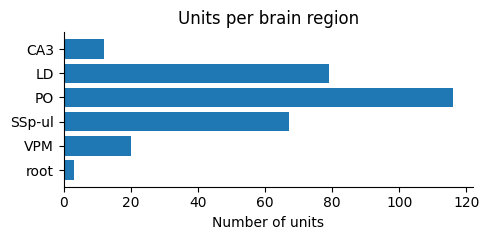

In [5]:
regions, counts = np.unique(data.units.region_beryl.astype(str), return_counts=True)

fig, ax = plt.subplots(figsize=(5, 2.5))
ax.barh(regions, counts)
ax.invert_yaxis()
ax.set(xlabel="Number of units", title="Units per brain region")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## A Single Forward Pass

NuCLR processes a recording one `ctx_duration`-long window (20 s) at a time.
`get_input_fn` returns a transform that turns a `Data` slice into model inputs:
- **`bins`**: spike counts in 20 ms bins, with one row per unit that spikes in the window.
- **`group_lengths`**: the number of units in each spatial attention group. With `group_by="probe_id"`, units only attend to units on the same probe.

When training, this transform is meant to be the last transform of a `Dataset`, with batches assembled by `collate`.

Let's run it on the first window of the recording.
Since the window is 20 s long and the bins are 20 ms, we should get 1000 bins per unit.

In [6]:
input_fn = model.get_input_fn(group_by="probe_id")
# input_fn will turn a `Data` slice into inputs for the model's forward pass.

start = data.domain.start[0]
sample = input_fn(data.slice(start, start + model.ctx_duration))
batch = collate([sample])
print("bins:", tuple(batch["bins"].shape), "group_lengths:", batch["group_lengths"].tolist())

model.eval()
with torch.no_grad():
    z = model(batch["bins"].to(device), batch["group_lengths"].to(device))
print("embeddings:", tuple(z.shape))

bins: (256, 1000) group_lengths: [256]


embeddings: (256, 256)


Notice that only 256 of the 297 units are in `bins`: the others don't spike in this window, so they are dropped.
The model returns one 256-dimensional embedding per unit.

## Embed the Entire Session

NuCLR is meant to be used to get one embedding per neuron.
The suggested way to do this is to embed every `ctx_duration`-long window of the session in a sliding window fashion (with a step of half a window), and to average the embeddings of each neuron over the windows in which it spikes.
`NuCLR.embed` is a convenient way of doing this. Neurons that never spike get `NaN` embeddings.

This takes ~3 s on an RTX5090, and ~2.5 minutes on a 32-core CPU.
On a CPU, you can set `MAX_MINUTES` to only embed the start of the recording.

In [7]:
MAX_MINUTES = None  # e.g. 10 to only embed the first 10 minutes

if MAX_MINUTES is not None:
    data = data.slice(data.domain.start[0], data.domain.start[0] + 60 * MAX_MINUTES)

emb = model.embed(data).cpu().numpy()
print("embeddings:", emb.shape)

embeddings: (297, 256)


Finally, let's visualize the embeddings with UMAP, colored by brain region.

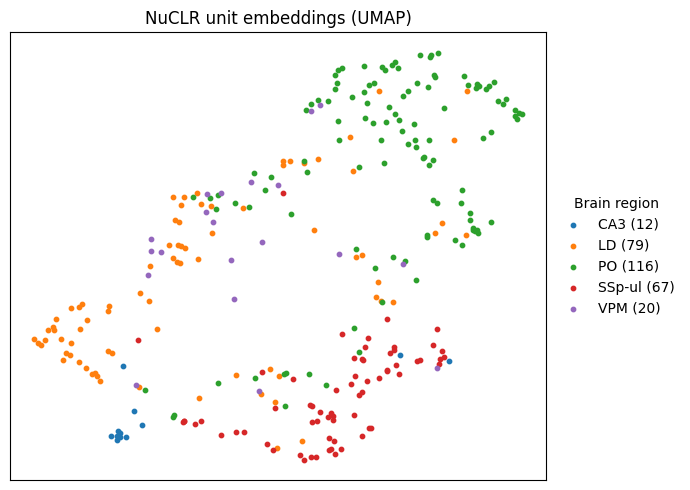

In [8]:
region = data.units.region_beryl.astype(str)
keep = ~np.isnan(emb).any(1) & ~np.isin(region, ["root", "void"])  # "root" and "void" are not real regions.
x, y = normalize(emb[keep]), region[keep]

xy = umap.UMAP(random_state=0).fit_transform(x)

fig, ax = plt.subplots(figsize=(7, 5))
for r in np.unique(y):
    ax.scatter(*xy[y == r].T, s=10, label=f"{r} ({(y == r).sum()})")
ax.set(xticks=[], yticks=[], title="NuCLR unit embeddings (UMAP)")
ax.legend(title="Brain region", frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
plt.show()

The model only sees spikes, yet units from the same region end up close to each other, *including* neighboring thalamic nuclei (LD, PO and VPM).

## Things to Try

- Load another checkpoint, from `nuclr_43.pt` to `nuclr_46.pt`.
- Color the embeddings by a coarser region level, such as `region_cosmos`.
- Embed your own recordings: `NuCLR.embed` works on any `Data` object with `spikes` and `units` (see `NuCLR.get_input_fn` for the expected attributes).